In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

In [2]:
data_path = Path.cwd() / "../data"
os.chdir(data_path)

file_names = [p.name[:-5] for p in data_path.iterdir() if p.is_file()]
print(file_names)

data = {}
for name in file_names:
    with open(data_path / f'{name}.json', encoding='utf-8') as f:
        data[name] = json.load(f)
bus = data['bus_params']

for idx in range(len(bus[0]["energy_price_DKK_per_kWh"])):
    print(f"Hour {idx} price: ", bus[0]["energy_price_DKK_per_kWh"][idx])

#Import/Export prices
print(f'Import price: ', bus[0]['import_tariff_DKK_per_kWh'], '\nExport price: ',
 bus[0]['export_tariff_DKK_per_kWh'])

['appliance_params', 'bus_params', 'params_Q1_caseA', 'params_Q1_caseB', 'params_Q2_linear', 'params_Q2_quadratic', 'params_Q3', 'params_Q3_battery']
Hour 0 price:  1.1
Hour 1 price:  1.05
Hour 2 price:  1.0
Hour 3 price:  0.9
Hour 4 price:  0.85
Hour 5 price:  1.01
Hour 6 price:  1.05
Hour 7 price:  1.2
Hour 8 price:  1.4
Hour 9 price:  1.6
Hour 10 price:  1.5
Hour 11 price:  1.1
Hour 12 price:  1.05
Hour 13 price:  1.0
Hour 14 price:  0.95
Hour 15 price:  1.0
Hour 16 price:  1.2
Hour 17 price:  1.5
Hour 18 price:  2.1
Hour 19 price:  2.5
Hour 20 price:  2.2
Hour 21 price:  1.8
Hour 22 price:  1.4
Hour 23 price:  1.2
Import price:  0.5 
Export price:  0.4


In [3]:
P_price_per_kwh = bus[0]['energy_price_DKK_per_kWh']
export_price = bus[0]['export_tariff_DKK_per_kWh']
import_price = bus[0]['import_tariff_DKK_per_kWh']

hours_u_greater_p_imp = []
hours_u_lesser_p_exp = []

for h in range(24):
    pt_imp = P_price_per_kwh[h] + export_price
    pt_exp = P_price_per_kwh[h] - import_price

    #Consumption utility for problem 1
    u = data['appliance_params']['loads'][0]['consumption_utility_DKK_per_kWh']

    if u > pt_imp:
        hours_u_greater_p_imp.append(h)
    elif u < pt_exp:
        hours_u_lesser_p_exp.append(h)

print('Import: ', hours_u_greater_p_imp, '\n', 'Export: ', hours_u_lesser_p_exp, sep ='')

Import: [2, 3, 4, 5, 13, 14, 15]
Export: [18, 19, 20]


In [4]:
c_pv_a = data['appliance_params']['DERs'][0]['marginal_cost_DKK_per_kWh']
c_pv_b = data['appliance_params']['DERs'][1]['marginal_cost_DKK_per_kWh']
u = data['appliance_params']['loads'][0]['consumption_utility_DKK_per_kWh']

print('Case A: ', round(u - c_pv_a, 2))
print('Case B: ', round(u - c_pv_b, 2))

Case A:  0.02
Case B:  -0.04


In [5]:
min_energy = data['appliance_params']['loads'][3]['min_total_energy_per_day_kWh']

ref_lod_cap_factor = data['appliance_params']['loads'][
    3]['reference_load_capacity_factor']
max_load_kWh_per_hour = data['appliance_params']['loads'][3]['max_load_KWh_per_hour']

lt_ref = round(sum([max_load_kWh_per_hour * ref_lod_cap_factor[x]
               for x in range(len(ref_lod_cap_factor))]), 2)
print('lt_ref: ', lt_ref)

lt_ref:  32.34


In [6]:
# PV_01_A 0 -> max_power_kW
# ref_load_cap_factor_fl2l = data['appliance_params']['loads'][1]['reference_load_capacity_factor']
# ref_load_cap_factor_fl2q = data['appliance_params']['loads'][2]['reference_load_capacity_factor']
# ref_load_cap_factor_fl3 = data['appliance_params']['loads'][3]['reference_load_capacity_factor']

# max_load_kWh_per_hour = data['appliance_params']['loads'][0]['max_load_KWh_per_hour']

max_power_kW = data['appliance_params']['DERs'][0]['max_power_kW']
hourly_profile_ratio = data['appliance_params']['DERs'][0]['hourly_profile_ratio']

pv_available = [max_power_kW * r for r in hourly_profile_ratio]
print('PV hours:', [h for h in range(24) if pv_available[h] > 0])
print('Total PV:', round(sum(pv_available), 2))


for h in [18, 19]:
    p_imp = P_price_per_kwh[h] + import_price
    p_exp = P_price_per_kwh[h] - export_price
    print(f'Hour {h}: PV = {pv_available[h]:.2f} kWh, p = {P_price_per_kwh[h]:.2f}, ' 
          f'p_imp = {p_imp:.2f}, p_exp = {p_exp:.2f}')


PV hours: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Total PV: 26.94
Hour 18: PV = 1.50 kWh, p = 2.10, p_imp = 2.60, p_exp = 1.70
Hour 19: PV = 1.50 kWh, p = 2.50, p_imp = 3.00, p_exp = 2.10


In [7]:
import sys
sys.path.append('..')

from src.data_loader import load_question
from src.model_q2 import LinearDisutilityModel

data = load_question("Q2_linear")
results = LinearDisutilityModel(data).build().solve()

print(results)
results.hourly
results.objective
results.save("results/Q2_linear")

Set parameter Username
Set parameter LicenseID to value 2859426
Academic license - for non-commercial use only - expires 2027-09-01


status: OPTIMAL | objective: 44.31 DKK
daily totals (kWh): load=23.1, pv=26.1, import=0.0, export=3.0


## Extra Plots for Q2 b) LinearDisutility

In [8]:
import sys
sys.path.append('..')

from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q2 import LinearDisutilityModel

OUT = Path(src.__file__).resolve().parents[1] / "results" / "Q2_linear"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})


def run(data, c_L):
    """Solve the linear-disutility model for one value of c_L (DKK/kWh) and return (results, metrics)."""
    d = replace(data, linear_disutility=float(c_L))
    res = LinearDisutilityModel(d).build().solve()
    h = res.hourly
    dev = (h["dev_up"] + h["dev_down"]).sum()
    at_bound = (h["reference_load"] > 0) & (h["load"] <= d.load_min_kWh + 1e-9)
    return res, {
        "energy_kWh": h["load"].sum(),
        "procurement_DKK": res.objective - c_L * dev,
        "disutility_DKK": c_L * dev,
        "objective_DKK": res.objective,
        "abs_deviation_kWh": dev,
        "hours_at_bound": int(at_bound.sum()),
    }


data = load_question("Q2_linear")
results, base = run(data, data.linear_disutility)
hr = results.hourly
hours = hr.index.to_numpy()
p_imp = data.energy_price + data.import_tariff
p_exp = data.energy_price - data.export_tariff


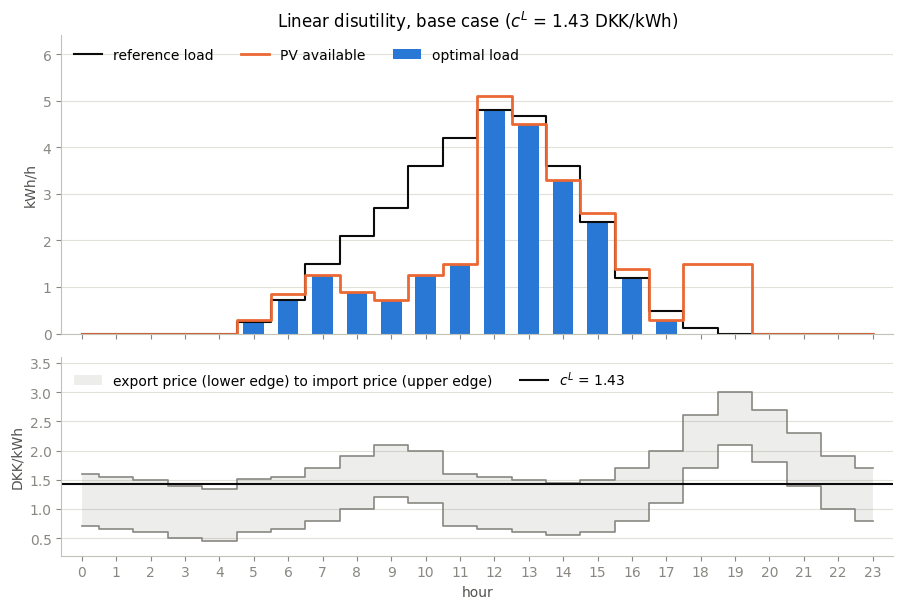

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, height_ratios=[3, 2])

ax1.bar(hours, hr["load"], width=0.6, color=BLUE, label="optimal load")
ax1.step(hours, hr["reference_load"], where="mid", color=INK, lw=1.5, label="reference load")
ax1.step(hours, hr["pv_available"], where="mid", color=ORANGE, label="PV available")
ax1.set(ylabel="kWh/h", ylim=(0, 6.4),
        title=f"Linear disutility, base case ($c^L$ = {data.linear_disutility} DKK/kWh)")
ax1.legend(ncol=3, loc="upper left")

ax2.fill_between(hours, p_exp, p_imp, step="mid", color=GREY, alpha=0.15, lw=0,
                 label="export price (lower edge) to import price (upper edge)")
ax2.step(hours, p_imp, where="mid", color=GREY, lw=1.2)
ax2.step(hours, p_exp, where="mid", color=GREY, lw=1.2)
ax2.axhline(data.linear_disutility, color=INK, lw=1.5, label=f"$c^L$ = {data.linear_disutility}")
ax2.set(xlabel="hour", ylabel="DKK/kWh", xticks=hours, xlim=(-0.6, 23.6), ylim=(0.2, 3.6))
ax2.legend(ncol=2, loc="upper left")

fig.tight_layout()
fig.savefig(OUT / "q2b_base_case.png", dpi=150)


predicted thresholds: [1.41, 1.45, 1.5, 1.6, 1.7, 1.9, 2.0, 2.1]


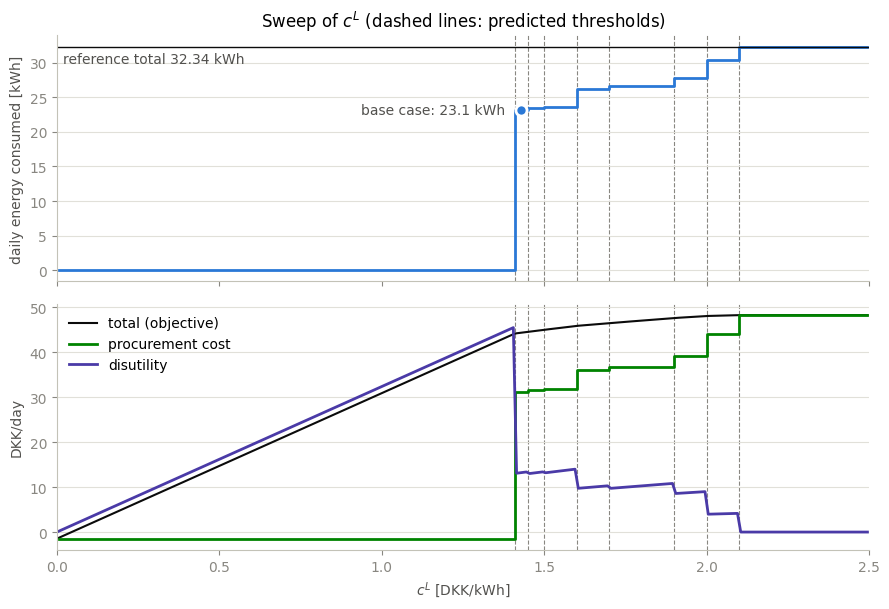

In [10]:
c_values = np.round(np.arange(0.005, 2.5, 0.01), 3)
sweep = pd.DataFrame({c: run(data, c)[1] for c in c_values}).T
sweep.index.name = "c_L"

a = np.median([p_exp, np.full(len(hours), data.pv_marginal_cost), p_imp], axis=0)
ref, pv_max = data.reference_load, data.pv_available
thresholds = sorted({float(x) for x in np.round(a[np.minimum(ref, pv_max) > 0], 2)}
                    | {float(x) for x in np.round(p_imp[ref > pv_max], 2)})
print("predicted thresholds:", thresholds)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)
for ax in (ax1, ax2):
    for th in thresholds:
        ax.axvline(th, color=GREY, lw=0.8, ls="--", zorder=0)

ax1.plot(sweep.index, sweep["energy_kWh"], color=BLUE, drawstyle="steps-mid")
ax1.axhline(ref.sum(), color=INK, lw=1)
ax1.text(0.02, ref.sum() - 0.8, f"reference total {ref.sum():.2f} kWh", va="top", color="#52514e")
ax1.plot(data.linear_disutility, base["energy_kWh"], "o", color=BLUE, ms=8, mec="white", mew=2)
ax1.annotate(f"base case: {base['energy_kWh']:.1f} kWh", (data.linear_disutility, base["energy_kWh"]),
             xytext=(-12, 0), textcoords="offset points", ha="right", va="center", color="#52514e")
ax1.set(ylabel="daily energy consumed [kWh]", title="Sweep of $c^L$ (dashed lines: predicted thresholds)")

ax2.plot(sweep.index, sweep["objective_DKK"], color=INK, lw=1.5, label="total (objective)")
ax2.plot(sweep.index, sweep["procurement_DKK"], color=GREEN, drawstyle="steps-mid", label="procurement cost")
ax2.plot(sweep.index, sweep["disutility_DKK"], color=VIOLET, label="disutility")
ax2.set(xlabel="$c^L$ [DKK/kWh]", ylabel="DKK/day", xlim=(0, 2.5))
ax2.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT / "q2b_sweep.png", dpi=150)


In [11]:
table = pd.DataFrame({c: run(data, c)[1] for c in [1.0, 1.43, 1.55, 1.65, 1.80, 1.95, 2.05, 2.20]}).T
table.index.name = "c_L"
table = table.astype({"hours_at_bound": int})
table.round(2)


,energy_kWh,procurement_DKK,disutility_DKK,objective_DKK,abs_deviation_kWh,hours_at_bound
c_L,,,,,,
1.00,0.00,-1.47,32.34,30.87,32.34,14
1.43,23.10,31.10,13.21,44.31,9.24,1
1.55,23.58,31.81,13.58,45.38,8.76,1
1.65,26.28,36.13,10.00,46.13,6.06,1
1.80,26.64,36.74,10.26,47.00,5.70,0
1.95,27.84,39.02,8.78,47.79,4.50,0
2.05,30.36,44.06,4.06,48.12,1.98,0
2.20,32.34,48.22,0.00,48.22,0.00,0


## Extra Plots for Q2 c) Quadratic Disutility